
  # Payoffs al vencimiento y análisis de sensibilidad
  Carlos Romo · 02/09/2026

Este notebook estudia cómo responden los payoffs de opciones europeas **call** y **put** ante cambios en volatilidad, rendimiento, plazo y precio de ejercicio.

## Mapa del análisis

| Sección | Pregunta central | Resultado esperado |
|:--|:--|:--|
| **1. Payoff al vencimiento** | ¿Cuándo se ejerce cada opción? | Call: $\max(S_T-K,0)$ · Put: $\max(K-S_T,0)$ |
| **2. Escenario base** | ¿Cómo se distribuyen $S_T$ y los payoffs? | Muchos payoffs son cero; la distribución es asimétrica |
| **3. Sensibilidades** | ¿Qué cambia al variar $\sigma$, $r$, $T$ o $K$? | Efectos distintos para calls y puts |
| **4. Conclusiones** | ¿Qué intuiciones son robustas? | La convexidad explica gran parte de los resultados |

<div class="callout note-card">
  <strong>Alcance.</strong> Los cálculos reportan el <em>payoff promedio al vencimiento</em>. No deben leerse directamente como primas o precios actuales. Si la dinámica se interpreta bajo la medida neutral al riesgo, el valor presente estimado sería $e^{-rT}\,\mathbb{E}[\text{payoff}]$.
</div>

## 0. Preparación del entorno

Se importan las librerías numéricas y de visualización que se usarán durante el análisis.

In [52]:
import numpy as np
import matplotlib.pyplot as plt

In [53]:
# Estilo visual añadido; no altera los cálculos del código original
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({
    "figure.figsize": (8.5, 4.8),
    "figure.dpi": 110,
    "axes.titlesize": 15,
    "axes.labelsize": 11,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "grid.alpha": 0.25,
})
CALL_COLOR = "#2563eb"
PUT_COLOR = "#e11d48"

## 1. Payoffs al vencimiento

Sea $S_T$ el precio del activo al vencimiento y $K$ el precio de ejercicio. El payoff es una función **convexa**: el comprador limita su pérdida a la prima pagada, mientras conserva una exposición favorable cuando la opción termina *in the money*.

### 1.1 Call

$$\text{Payoff}_{call}=\max(S_T-K,0)$$

La call se ejerce cuando $S_T>K$. Por debajo de $K$, su payoff al vencimiento es cero.

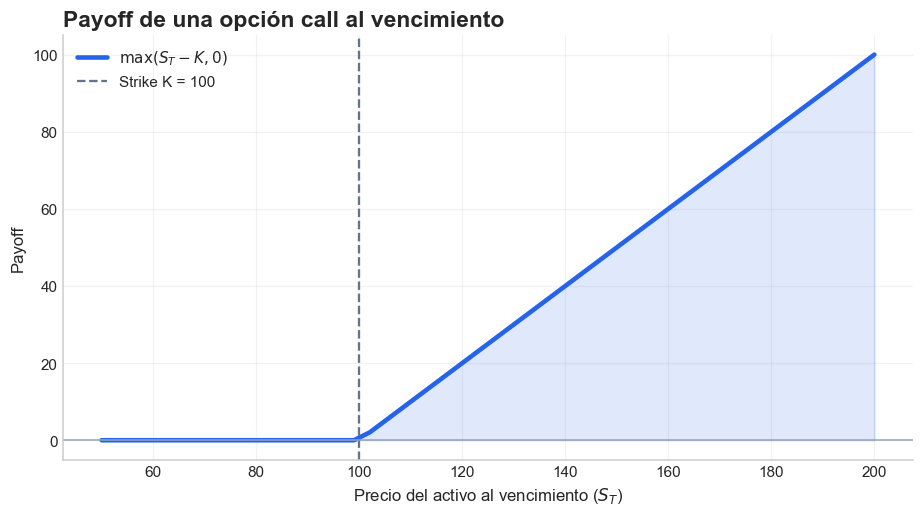

In [54]:

k=100
sT=np.linspace(50,200)
payoff_call= np.maximum(sT-k,0)

plt.figure(figsize=(8.5, 4.8))
plt.plot(sT, payoff_call, color=CALL_COLOR, linewidth=3,
         label=r"$\max(S_T-K,0)$")
plt.fill_between(sT, payoff_call, 0, color=CALL_COLOR, alpha=0.14)
plt.axvline(k, color="#64748b", linestyle="--", linewidth=1.5,
            label=f"Strike K = {k}")
plt.axhline(0, color="#94a3b8", linewidth=1)
plt.title("Payoff de una opción call al vencimiento", loc="left", fontweight="bold")
plt.xlabel(r"Precio del activo al vencimiento ($S_T$)")
plt.ylabel("Payoff")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()


 A partir del strike $K=100$, cada unidad adicional en ST incrementa el payoff de la call en una unidad. Para el comprador, el potencial de ganancia bruta es ilimitado; para el vendedor de una call descubierta, la pérdida potencial también lo es.

### 1.2 Put

$$\text{Payoff}_{put}=\max(K-S_T,0)$$

La put se ejerce cuando $S_T<K$. Por encima de $K$, su payoff al vencimiento es cero.

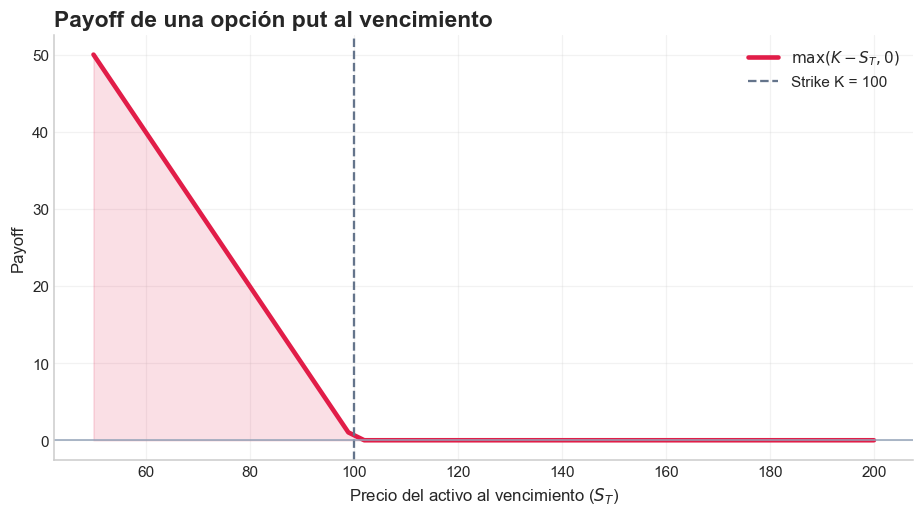

In [55]:
payoff_put= np.maximum(k-sT,0)

plt.figure(figsize=(8.5, 4.8))
plt.plot(sT, payoff_put, color=PUT_COLOR, linewidth=3,
         label=r"$\max(K-S_T,0)$")
plt.fill_between(sT, payoff_put, 0, color=PUT_COLOR, alpha=0.14)
plt.axvline(k, color="#64748b", linestyle="--", linewidth=1.5,
            label=f"Strike K = {k}")
plt.axhline(0, color="#94a3b8", linewidth=1)
plt.title("Payoff de una opción put al vencimiento", loc="left", fontweight="bold")
plt.xlabel(r"Precio del activo al vencimiento ($S_T$)")
plt.ylabel("Payoff")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()



  <strong>Lectura.</strong> Por debajo de $K=100$, cada unidad que pierde el activo incrementa en una unidad el payoff de la put. A diferencia de la call, su payoff máximo está acotado por K.

| Región al vencimiento | Call | Put |
|:--|:--:|:--:|
| $S_T<K$ | Out the Money | In the Money |
| $S_T=K$ | Payoff 0 | Payoff 0 |
| $S_T>K$ | In the Money | Out the Money |

## 2. Simulación del escenario base

El precio terminal se modela mediante un movimiento browniano geométrico:

$$S_T=S_0\exp\left[\left(r-\frac{1}{2}\sigma^2\right)T+\sigma\sqrt{T}\,Z\right],\qquad Z\sim\mathcal{N}(0,1).$$

| Parámetro | Valor base | Interpretación |
|:--|--:|:--|
| $S_0$ | 100 | Precio inicial |
| $K$ | 100 | Strike; opción *at the money* al inicio |
| $r$ | 5% | Rendimiento usado como drift |
| $\sigma$ | 20% | Volatilidad anual |
| $T$ | 1 año | Horizonte |
| Simulaciones efectivas | 10,000 | Tamaño de la muestra generado |

In [56]:
np.random.seed(42)
s0=100
k=100
r=0.05
vol=0.2
periodo=1
M=10**3
sT=s0*np.exp((r-1/2*vol**2)*periodo + (vol*np.sqrt(periodo)*np.random.normal(0,1,10000)))

### 2.1 Distribución del precio terminal

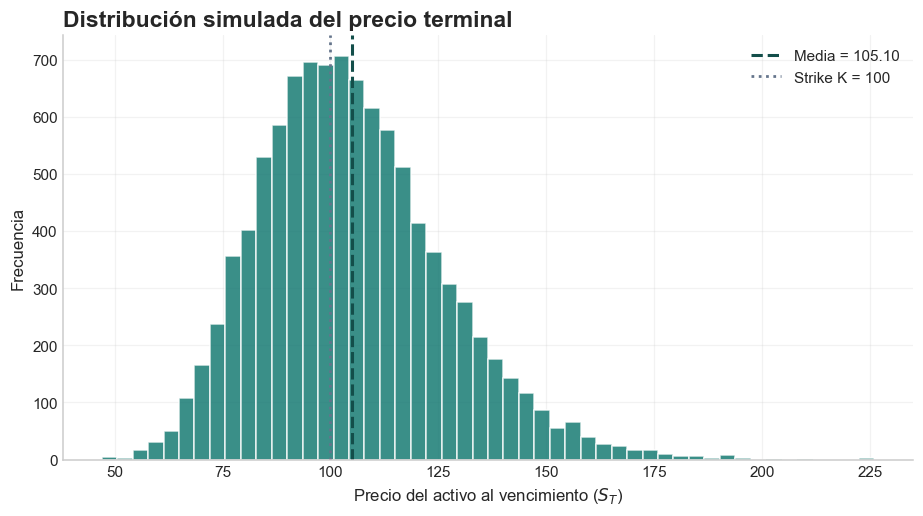

In [57]:
plt.figure(figsize=(8.5, 4.8))
plt.hist(sT, bins=50, color="#0f766e", alpha=0.82, edgecolor="white")
plt.axvline(np.mean(sT), color="#134e4a", linestyle="--", linewidth=2,
            label=f"Media = {np.mean(sT):.2f}")
plt.axvline(k, color="#64748b", linestyle=":", linewidth=1.8,
            label=f"Strike K = {k}")
plt.title("Distribución simulada del precio terminal", loc="left", fontweight="bold")
plt.xlabel(r"Precio del activo al vencimiento ($S_T$)")
plt.ylabel("Frecuencia")
plt.legend(frameon=False)
plt.tight_layout()
plt.show()



  <strong>Lectura.</strong> $S_T$ sigue una distribución lognormal: nunca toma valores negativos y presenta una cola derecha más larga. Esa asimetría se transmite a los payoffs, pero el operador $\max(\cdot,0)$ acumula en cero todos los escenarios fuera del dinero.

### 2.2 Distribución del payoff de la call

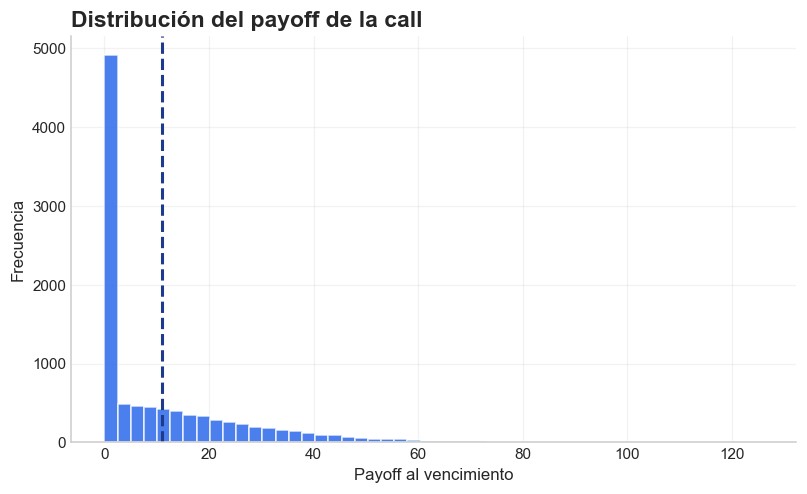

Payoff promedio de la put: 10.9860


In [58]:
payoffs= np.maximum(sT-k,0)

plt.figure(figsize=(8.5, 4.8))
plt.hist(payoffs, bins=50, color=CALL_COLOR, alpha=0.82, edgecolor="white")
plt.axvline(np.mean(payoffs), color="#1e3a8a", linestyle="--", linewidth=2,
            label=f"Media = {np.mean(payoffs):.2f}")
plt.title("Distribución del payoff de la call", loc="left", fontweight="bold")
plt.xlabel("Payoff al vencimiento")
plt.ylabel("Frecuencia")
plt.show()
print(f"Payoff promedio de la put: {np.mean(payoffs):.4f}")


Resultado base — call. El payoff promedio simulado es aproximadamente 10.99. La masa en cero corresponde a escenarios con $S_T\geq K$ ; la cola derecha recoge los escenarios favorables sin un límite superior.

### 2.3 Distribución del payoff de la put

Se replica el análisis anterior usando $\max(K-S_T,0)$.

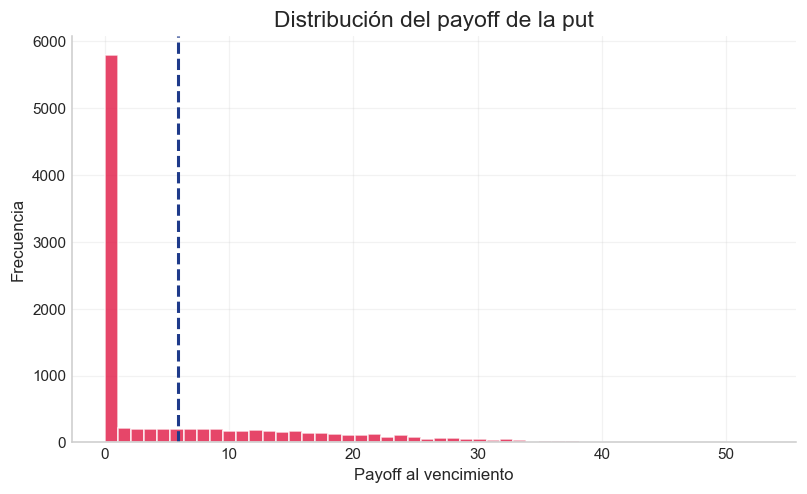

Payoff promedio de la put: 5.8889


In [59]:
payoffs_put = np.maximum(k-sT, 0)
plt.hist(payoffs_put, bins=50, color=PUT_COLOR, alpha=0.82, edgecolor="white")
plt.title("Distribución del payoff de la put")
plt.axvline(np.mean(payoffs_put), color="#1e3a8a", linestyle="--", linewidth=2,
            label=f"Media = {np.mean(payoffs_put):.2f}")
plt.xlabel("Payoff al vencimiento")
plt.ylabel("Frecuencia")
plt.show()
print(f"Payoff promedio de la put: {np.mean(payoffs_put):.4f}")


  Resultado base — put. El payoff promedio simulado es aproximadamente 5.89. También aparece una concentración en cero, ahora formada por los escenarios con $S_T\geq K$. Su cola está acotada porque, con $S_T\geq0$, el payoff no puede exceder $K$.

## 3. Análisis de sensibilidad

En cada bloque se conserva el escenario base y se cambia una sola variable. Las líneas comparativas usan los mismos shocks aleatorios para call y put dentro de cada escenario, lo que facilita atribuir las diferencias al parámetro analizado.

### 3.1 Volatilidad $\sigma$

Primero se observa el payoff promedio de la **call** para volatilidades de 10%, 20%, 40% y 60%.

In [60]:
np.random.seed(42)
vol=[.1,.2,.4,.6]
for i in vol:
    sT=s0*np.exp((r-1/2*i**2)*periodo + (i*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    payoffs= np.maximum(sT-k,0)
    print(f"con volatilidad del {i}: {np.mean(payoffs)}")

con volatilidad del 0.1: 7.149025780427269
con volatilidad del 0.2: 11.155234901224286
con volatilidad del 0.4: 18.439681503755292
con volatilidad del 0.6: 26.736150213390367


**Put y comparación visual**

put con volatilidad del 0.1: 2.0407297992252103
put con volatilidad del 0.2: 5.739739935196206
put con volatilidad del 0.4: 13.97997292973012
put con volatilidad del 0.6: 21.938347798114812


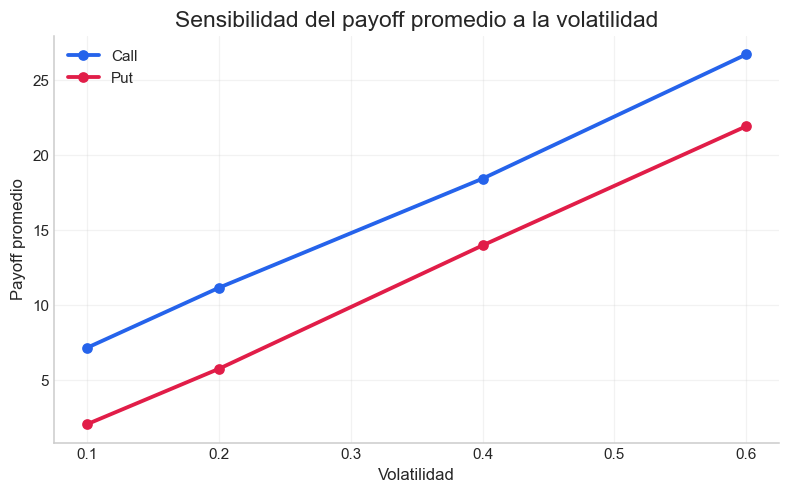

In [61]:
np.random.seed(42)
call_vol_means = []
put_vol_means = []
for i in vol:
    sT_put = s0*np.exp((r-1/2*i**2)*periodo + (i*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    call_vol_means.append(np.mean(np.maximum(sT_put-k, 0)))
    put_vol_means.append(np.mean(np.maximum(k-sT_put, 0)))
    print(f"put con volatilidad del {i}: {put_vol_means[-1]}")

plt.plot(vol, call_vol_means, marker="o", linewidth=2.5, color=CALL_COLOR, label="Call")
plt.plot(vol, put_vol_means, marker="o", linewidth=2.5, color=PUT_COLOR, label="Put")
plt.title("Sensibilidad del payoff promedio a la volatilidad")
plt.xlabel("Volatilidad")
plt.ylabel("Payoff promedio")
plt.legend(frameon=False)
plt.show()


   Al aumentar la volatilidad, sube el payoff promedio tanto de la call como de la put. La razón central es la <strong>convexidad</strong>: los movimientos favorables amplían el payoff, mientras que los desfavorables no pueden llevarlo por debajo de cero. Esta conclusión supone que los demás parámetros permanecen constantes.

### 3.2 Rendimiento o drift $r$

El código usa $r$ dentro de la dinámica de $S_T$. Un valor mayor desplaza la distribución del precio terminal hacia arriba.

In [62]:
np.random.seed(42)
s0=100
k=100
vol=0.2
periodo=1
ren=[.05,.1,.2]
for i in ren:
    sT=s0*np.exp((i-1/2*vol**2)*periodo + (vol*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    payoffs= np.maximum(sT-k,0)
    print(f"con rendimiento del {i}: {np.mean(payoffs)}")

con rendimiento del 0.05: 10.985961590306978
con rendimiento del 0.1: 14.865957903017716
con rendimiento del 0.2: 23.634985960758737


**Put y comparación visual**

put con rendimiento del 0.05: 5.888923357157859
put con rendimiento del 0.1: 4.0456949350601334
put con rendimiento del 0.2: 1.8401060154557352


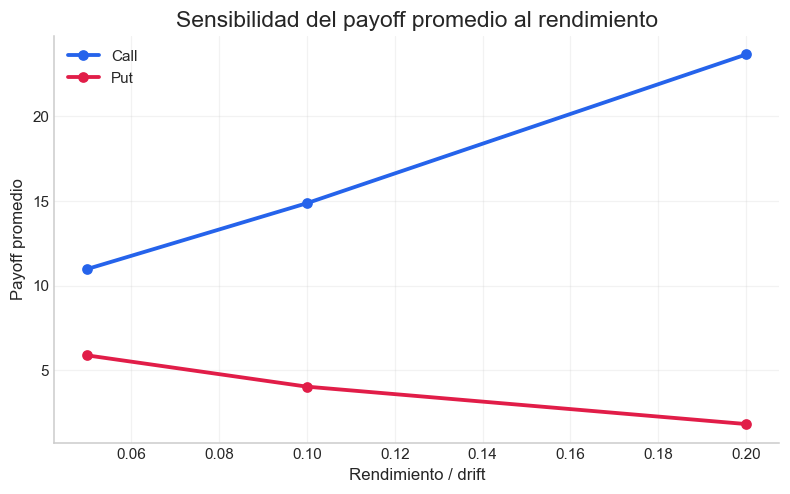

In [63]:
np.random.seed(42)
call_r_means = []
put_r_means = []
for i in ren:
    sT_put = s0*np.exp((i-1/2*vol**2)*periodo + (vol*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    call_r_means.append(np.mean(np.maximum(sT_put-k, 0)))
    put_r_means.append(np.mean(np.maximum(k-sT_put, 0)))
    print(f"put con rendimiento del {i}: {put_r_means[-1]}")

plt.plot(ren, call_r_means, marker="o", linewidth=2.5, color=CALL_COLOR, label="Call")
plt.plot(ren, put_r_means, marker="o", linewidth=2.5, color=PUT_COLOR, label="Put")
plt.title("Sensibilidad del payoff promedio al rendimiento")
plt.xlabel("Rendimiento / drift")
plt.ylabel("Payoff promedio")
plt.legend(frameon=False)
plt.show()

Cuando aumenta $r$, la distribución de $S_T$ se desplaza hacia precios más altos. Esto eleva la probabilidad y la magnitud de ejercicio de la <strong>call</strong>, pero reduce ambas para la <strong>put</strong>.Se vuelve menos probable terminar por debajo de $K$.

### 3.3 Tiempo al vencimiento $T$

Se comparan horizontes de 0.25, 0.5, 1 y 2 años.

In [64]:
np.random.seed(42)
s0=100
k=100
vol=0.2
periodo=[0.25,.5,1,2]
r=0.05
for i in periodo:
    sT=s0*np.exp((r-1/2*vol**2)*i + (vol*np.sqrt(i)*np.random.normal(0,1,10000)))
    payoffs= np.maximum(sT-k,0)
    print(f"con periodo del {i}: {np.mean(payoffs)}")

con periodo del 0.25: 4.671344053241657
con periodo del 0.5: 7.171322842273846
con periodo del 1: 10.761690391171063
con periodo del 2: 17.754725865082083


**Put y comparación visual**

put con periodo del 0.25: 3.431620107999949
put con periodo del 0.5: 4.4416659210381395
put con periodo del 1: 5.93186573451646
put con periodo del 2: 7.436658105440113


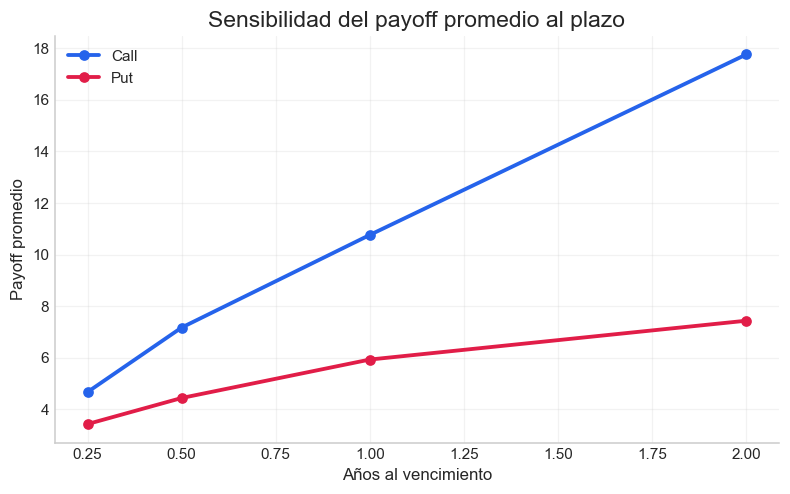

In [65]:
np.random.seed(42)
call_t_means = []
put_t_means = []
for i in periodo:
    sT_put = s0*np.exp((r-1/2*vol**2)*i + (vol*np.sqrt(i)*np.random.normal(0,1,10000)))
    call_t_means.append(np.mean(np.maximum(sT_put-k, 0)))
    put_t_means.append(np.mean(np.maximum(k-sT_put, 0)))
    print(f"put con periodo del {i}: {put_t_means[-1]}")

plt.plot(periodo, call_t_means, marker="o", linewidth=2.5, color=CALL_COLOR, label="Call")
plt.plot(periodo, put_t_means, marker="o", linewidth=2.5, color=PUT_COLOR, label="Put")
plt.title("Sensibilidad del payoff promedio al plazo")
plt.xlabel("Años al vencimiento")
plt.ylabel("Payoff promedio")
plt.legend(frameon=False)
plt.show()


 En esta simulación, un plazo mayor incrementa la dispersión de $S_T$ y eleva el payoff promedio de ambas opciones. Para la call también contribuye el drift positivo. 

El efecto del plazo **no es universal para una put valorada hoy**: tasas positivas, dividendos, moneyness y descuento pueden contrarrestar el beneficio de mayor dispersión.

### 3.4 Precio de ejercicio $K$

Se comparan strikes de 80, 90, 100, 110 y 120.

In [66]:
np.random.seed(42)
s0=100
k=[80,90,100,110,120]
vol=0.2
periodo=1
r=0.05
for i in k:
    sT=s0*np.exp((r-1/2*vol**2)*periodo + (vol*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    payoffs= np.maximum(sT-i,0)
    print(f"con strike del {i}: {np.mean(payoffs)}")

con strike del 80: 25.832973971854415
con strike del 90: 17.76000653847779
con strike del 100: 10.761690391171063
con strike del 110: 6.331777604651691
con strike del 120: 3.4132658709459966


**Put y comparación visual**

put con strike del 80: 0.735935738705293
put con strike del 90: 2.34451157244971
put con strike del 100: 5.93186573451646
put con strike del 110: 11.345674938760238
put con strike del 120: 18.153776386081027


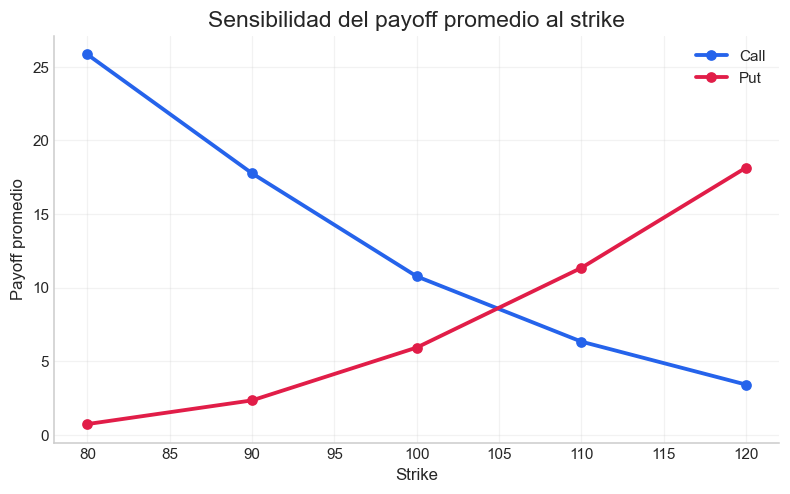

In [67]:
np.random.seed(42)
call_k_means = []
put_k_means = []
for i in k:
    sT_put = s0*np.exp((r-1/2*vol**2)*periodo + (vol*np.sqrt(periodo)*np.random.normal(0,1,10000)))
    call_k_means.append(np.mean(np.maximum(sT_put-i, 0)))
    put_k_means.append(np.mean(np.maximum(i-sT_put, 0)))
    print(f"put con strike del {i}: {put_k_means[-1]}")

plt.plot(k, call_k_means, marker="o", linewidth=2.5, color=CALL_COLOR, label="Call")
plt.plot(k, put_k_means, marker="o", linewidth=2.5, color=PUT_COLOR, label="Put")
plt.title("Sensibilidad del payoff promedio al strike")
plt.xlabel("Strike")
plt.ylabel("Payoff promedio")
plt.legend(frameon=False)
plt.show()


  Un strike más alto hace más difícil que la call termine In The Money, por lo que su payoff promedio disminuye. Para la put ocurre lo contrario: aumenta la región de ejercicio y también la magnitud $K-S_T$, por lo que su payoff promedio aumenta.

## 4. Conclusiones

### Resumen de sensibilidades

| Variable que aumenta | Payoff promedio call | Payoff promedio put | Intuición principal |
|:--|:--:|:--:|:--|
| $S_0$ | ↑ | ↓ | Desplaza $S_T$ hacia arriba |
| $K$ | ↓ | ↑ | Cambia el umbral y la magnitud de ejercicio |
| $\sigma$ | ↑ | ↑ | La convexidad se beneficia de mayor dispersión |
| $r$ o drift | ↑ | ↓ | Desplaza la distribución terminal hacia arriba |
| $T$ | ↑ en esta simulación | ↑ en esta simulación | Más dispersión; el efecto sobre valor presente puede depender de otras variables |

### Ideas clave

1. **Call y put son exposiciones complementarias.** Un desplazamiento al alza de $S_T$ favorece a la call y perjudica a la put; un strike mayor produce el patrón inverso.
2. **La volatilidad beneficia al comprador de opcionalidad.** La convexidad explica por qué aumenta el payoff promedio de ambas posiciones largas.
3. **Payoff y precio no son sinónimos.** Para pasar del promedio simulado a una prima teórica se requiere especificar una medida de valoración y descontar el payoff esperado.
4. **El riesgo del vendedor depende del contrato.** La call descubierta tiene pérdida potencial ilimitada; la pérdida de una put vendida está acotada por el strike, antes de considerar la prima.